# Experiment 9 :: Multiclass Cyberbullying Classification in Hinglish

- Dataset: [MC-Hinglish1.0](https://huggingface.co/datasets/sahinurlaskar/MC-Hinglish1.0), code-mixed Hindi-English tweets in seven classes
- Classical models on TF-IDF: Naive Bayes, Logistic Regression, Linear SVM
- Neural models: BiLSTM, mBERT, HingRoBERTa
- Scored with accuracy, macro F1 and weighted F1 on the official test split

The dataset contains abusive language. Run on a Colab T4 GPU.

In [1]:
%pip install -q transformers scikit-learn pandas matplotlib

In [2]:
import gc
import json
import math
import os
import random
import re
import time
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)
os.makedirs('outputs', exist_ok=True)


def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

Device: cuda


## 9.1 Data collection

In [3]:
base = 'https://huggingface.co/datasets/sahinurlaskar/MC-Hinglish1.0/resolve/main/'
raw_train = pd.read_csv(base + 'Train_data_MC-Hinglish1.0.csv')
raw_test = pd.read_csv(base + 'Test_data_MC-Hinglish1.0.csv')
print(raw_train.shape, raw_test.shape)
print(raw_train['cyberbullying_type'].value_counts())

(7400, 2) (1000, 2)
cyberbullying_type
not_cyberbullying    1491
gender               1004
abusive               989
offensive             980
mockery               980
religion              979
age                   977
Name: count, dtype: int64


## 9.2 Preprocessing

1. Unicode NFKC, lowercase, URLs and user mentions replaced by placeholders, hashtag symbol removed
2. Letters repeated three or more times shortened to two (`bhaiiii` becomes `bhaii`)
3. Empty rows and the 97 rows over 100 words dropped from train (long comments, the longest test tweet has 57 words)
4. Duplicates dropped from train, and train tweets that also occur in the test split dropped from train
5. The test split is cleaned as text but no row is removed

In [4]:
def clean(text):
    text = unicodedata.normalize('NFKC', str(text)).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' url ', text)
    text = re.sub(r'@\w+', ' user ', text)
    text = text.replace('#', ' ')
    text = re.sub(r'([a-z])\1{2,}', r'\1\1', text)
    return ' '.join(text.split())


assert clean('Bhaiiii @ram https://x.co') == 'bhaii user url'

train = raw_train.dropna().rename(columns={'cyberbullying_type': 'label'}).copy()
test = raw_test.rename(columns={'cyberbullying_type': 'label'}).copy()
train['text'], test['text'] = train['tweets'].map(clean), test['tweets'].map(clean)
stats = {'raw_train': len(raw_train), 'raw_test': len(raw_test)}
train = train[train['text'].str.len() > 0]
train = train[train['text'].str.split().str.len() <= 100]
stats['after_length_filter'] = len(train)
train = train.drop_duplicates('text')
stats['after_dedup'] = len(train)
train = train[~train['text'].isin(set(test['text']))].reset_index(drop=True)
stats['after_test_overlap_removed'] = len(train)

labels = sorted(train['label'].unique())
label_id = {l: i for i, l in enumerate(labels)}
train['y'], test['y'] = train['label'].map(label_id), test['label'].map(label_id)
assert test['y'].notna().all()

from sklearn.model_selection import train_test_split

fit, dev = train_test_split(train, test_size=0.1, random_state=42, stratify=train['y'])
stats.update(fit=len(fit), dev=len(dev), test=len(test))
print(stats)
train.groupby('label').head(1)[['text', 'label']]

{'raw_train': 7400, 'raw_test': 1000, 'after_length_filter': 7302, 'after_dedup': 7274, 'after_test_overlap_removed': 7243, 'fit': 6518, 'dev': 725, 'test': 1000}


,text,label
0,foundation x aata,mockery
2,chunna laga diya got real,offensive
3,"didi show off krri h ""left hand rule""",gender
11,aunty saans toh lelo,age
30,kya mtlb korean bolke nepali se kara diya,religion
44,merese toh imagine b nhi hora,not_cyberbullying
209,ye prateek sir tho chutiya hai ..,abusive


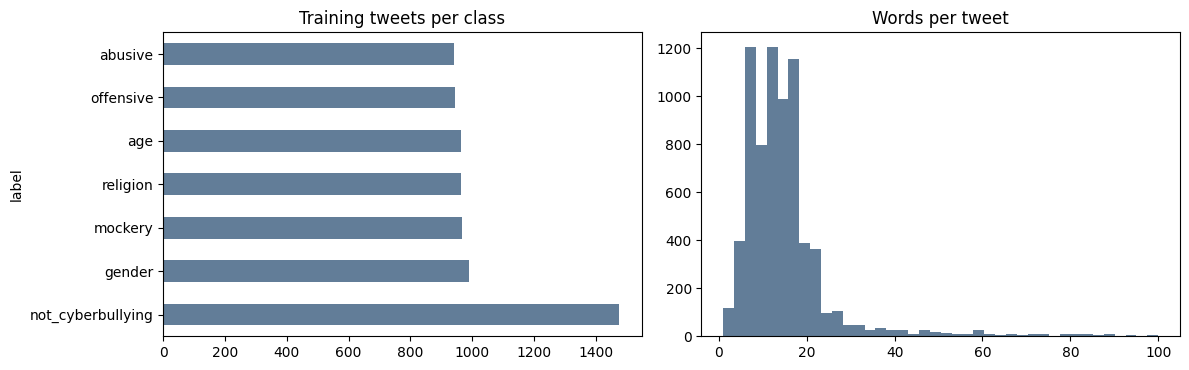

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
train['label'].value_counts().plot.barh(ax=axes[0], color='#627d98')
axes[0].set_title('Training tweets per class')
axes[1].hist(train['text'].str.split().str.len(), bins=40, color='#627d98')
axes[1].set_title('Words per tweet')
plt.tight_layout()
plt.show()

## 9.3 Evaluation

In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

results, predictions = {}, {}


def evaluate(name, predicted, dev_f1, seconds):
    predictions[name] = [int(p) for p in predicted]
    results[name] = {'accuracy': accuracy_score(test['y'], predicted), 'macro_f1': f1_score(test['y'], predicted, average='macro'),
                     'weighted_f1': f1_score(test['y'], predicted, average='weighted'), 'dev_macro_f1': dev_f1, 'seconds': seconds}
    print(name, {k: round(v, 4) for k, v in results[name].items()})

## 9.4 TF-IDF with classical models

Word 1-2 grams plus character 2-5 grams. Character n-grams cope with the many Hinglish spellings of one word. The regularisation strength is chosen on the dev split.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import FeatureUnion, make_pipeline
from sklearn.svm import LinearSVC


def features():
    return FeatureUnion([('word', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                         ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True))])


families = {'Naive Bayes': [lambda a=a: ComplementNB(alpha=a) for a in (0.1, 0.5, 1.0)],
            'Logistic Regression': [lambda c=c: LogisticRegression(C=c, max_iter=2000, class_weight='balanced') for c in (1, 5, 20)],
            'Linear SVM': [lambda c=c: LinearSVC(C=c, class_weight='balanced') for c in (0.1, 0.5, 1.0)]}
for name, options in families.items():
    start = time.time()
    best_f1, best_model = -1, None
    for option in options:
        candidate = make_pipeline(features(), option()).fit(fit['text'], fit['y'])
        f1 = f1_score(dev['y'], candidate.predict(dev['text']), average='macro')
        if f1 > best_f1:
            best_f1, best_model = f1, candidate
    evaluate(name, best_model.predict(test['text']), best_f1, time.time() - start)

Naive Bayes {'accuracy': 0.71, 'macro_f1': 0.687, 'weighted_f1': 0.6965, 'dev_macro_f1': 0.7969, 'seconds': 12.0042}
Logistic Regression {'accuracy': 0.722, 'macro_f1': 0.7084, 'weighted_f1': 0.716, 'dev_macro_f1': 0.8445, 'seconds': 84.7544}
Linear SVM {'accuracy': 0.737, 'macro_f1': 0.7193, 'weighted_f1': 0.7289, 'dev_macro_f1': 0.8499, 'seconds': 6.1704}


## 9.5 BiLSTM

In [8]:
from collections import Counter

seed_all()
counts = Counter(w for t in fit['text'] for w in t.split())
vocab = {w: i + 2 for i, w in enumerate(w for w, c in counts.items() if c >= 2)}
print('Vocabulary:', len(vocab))


def encode(texts, length=50):
    rows = [[vocab.get(w, 1) for w in t.split()[:length]] or [1] for t in texts]
    return torch.tensor([r + [0] * (length - len(r)) for r in rows])


class BiLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(vocab) + 2, 128, padding_idx=0)
        self.lstm = nn.LSTM(128, 128, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.4)
        self.output = nn.Linear(256, len(labels))

    def forward(self, x):
        hidden, _ = self.lstm(self.dropout(self.embedding(x)))
        hidden = hidden.masked_fill((x == 0).unsqueeze(-1), float('-inf')).amax(1)
        return self.output(self.dropout(hidden))


weights = torch.tensor(len(fit) / (len(labels) * fit['y'].value_counts().sort_index().values), dtype=torch.float32).to(device)
x_fit, y_fit = encode(fit['text']).to(device), torch.tensor(fit['y'].values).to(device)
x_dev, x_test = encode(dev['text']).to(device), encode(test['text']).to(device)
lstm = BiLSTM().to(device)
optimizer = torch.optim.Adam(lstm.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss(weight=weights)
best_f1, best_state, start = -1, None, time.time()
for epoch in range(12):
    lstm.train()
    for index in torch.randperm(len(x_fit), device=device).split(64):
        optimizer.zero_grad()
        loss_fn(lstm(x_fit[index]), y_fit[index]).backward()
        nn.utils.clip_grad_norm_(lstm.parameters(), 1.0)
        optimizer.step()
    lstm.eval()
    with torch.no_grad():
        f1 = f1_score(dev['y'], lstm(x_dev).argmax(1).cpu(), average='macro')
    print(epoch + 1, round(f1, 4))
    if f1 > best_f1:
        best_f1, best_state = f1, {k: v.clone() for k, v in lstm.state_dict().items()}
lstm.load_state_dict(best_state)
with torch.no_grad():
    evaluate('BiLSTM', lstm(x_test).argmax(1).cpu().numpy(), best_f1, time.time() - start)

Vocabulary: 6688
1 0.4179
2 0.5435
3 0.5864
4 0.6208
5 0.6541
6 0.662
7 0.6843
8 0.6811
9 0.6907
10 0.7102
11 0.7086
12 0.7233
BiLSTM {'accuracy': 0.62, 'macro_f1': 0.6086, 'weighted_f1': 0.6179, 'dev_macro_f1': 0.7233, 'seconds': 7.5086}


## 9.6 Fine-tuned transformers

mBERT is trained on 104 languages. HingRoBERTa is XLM-RoBERTa adapted to Romanised Hindi-English tweets. Same settings for both: AdamW, 2e-5, 5 epochs, batch size 32, best epoch chosen on dev macro F1.

In [9]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer


def run_transformer(name, checkpoint, epochs=5, batch_size=32, lr=2e-5):
    seed_all()
    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=len(labels)).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * math.ceil(len(fit) / batch_size)
    warmup = steps // 10
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min((s + 1) / warmup, max(0.0, (steps - s) / (steps - warmup))))
    texts, targets = fit['text'].tolist(), fit['y'].tolist()

    def batch_of(items):
        return tokenizer(items, return_tensors='pt', padding=True, truncation=True, max_length=128).to(device)

    def predict(items):
        model.eval()
        with torch.no_grad():
            return np.concatenate([model(**batch_of(items[i:i + 64])).logits.argmax(1).cpu().numpy() for i in range(0, len(items), 64)])

    best_f1, best_state, start = -1, None, time.time()
    for epoch in range(epochs):
        model.train()
        for index in torch.randperm(len(texts)).split(batch_size):
            optimizer.zero_grad()
            logits = model(**batch_of([texts[i] for i in index])).logits
            nn.functional.cross_entropy(logits, torch.tensor([targets[i] for i in index]).to(device), weight=weights).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
        f1 = f1_score(dev['y'], predict(dev['text'].tolist()), average='macro')
        print(name, epoch + 1, round(f1, 4))
        if f1 > best_f1:
            best_f1, best_state = f1, {k: v.cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    evaluate(name, predict(test['text'].tolist()), best_f1, time.time() - start)
    del model
    gc.collect()
    torch.cuda.empty_cache()


run_transformer('mBERT', 'google-bert/bert-base-multilingual-cased')
run_transformer('HingRoBERTa', 'l3cube-pune/hing-roberta')

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

... (11 outputs left out)

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: l3cube-pune/hing-roberta
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

HingRoBERTa 1 0.7087
HingRoBERTa 2 0.7787
HingRoBERTa 3 0.8042
HingRoBERTa 4 0.8259
HingRoBERTa 5 0.827
HingRoBERTa {'accuracy': 0.714, 'macro_f1': 0.6894, 'weighted_f1': 0.7009, 'dev_macro_f1': 0.827, 'seconds': 535.3763}


## 9.7 Model comparison

,accuracy,macro_f1,weighted_f1,dev_macro_f1,seconds
Naive Bayes,0.710,0.6870,0.6965,0.7969,12.0042
Logistic Regression,0.722,0.7084,0.7160,0.8445,84.7544
Linear SVM,0.737,0.7193,0.7289,0.8499,6.1704
BiLSTM,0.620,0.6086,0.6179,0.7233,7.5086
mBERT,0.651,0.6357,0.6445,0.8005,511.3240
HingRoBERTa,0.714,0.6894,0.7009,0.8270,535.3763


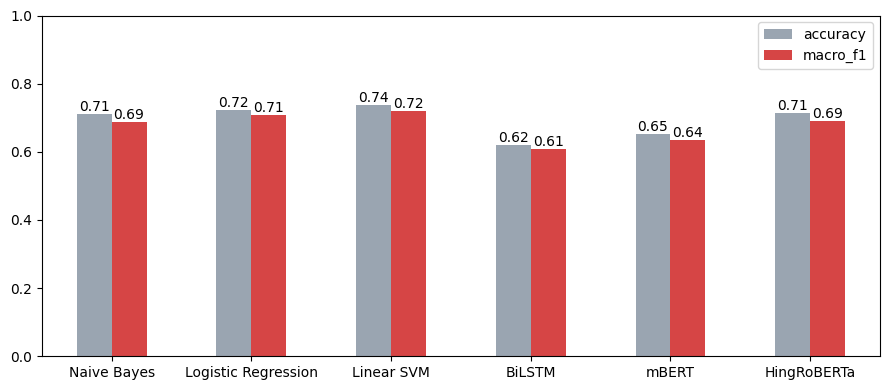

In [10]:
table = pd.DataFrame(results).T.round(4)
display(table)
ax = table[['accuracy', 'macro_f1']].plot.bar(figsize=(9, 4), color=['#9aa5b1', '#d64545'], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('outputs/comparison.png', dpi=160)
plt.show()

Best on dev: Linear SVM
                   precision    recall  f1-score   support

          abusive      0.748     0.642     0.691       148
              age      0.850     0.922     0.885       129
           gender      0.755     0.830     0.791       141
          mockery      0.485     0.386     0.430       127
not_cyberbullying      0.782     0.880     0.828       200
        offensive      0.602     0.548     0.574       124
         religion      0.813     0.863     0.837       131

         accuracy                          0.737      1000
        macro avg      0.719     0.724     0.719      1000
     weighted avg      0.726     0.737     0.729      1000



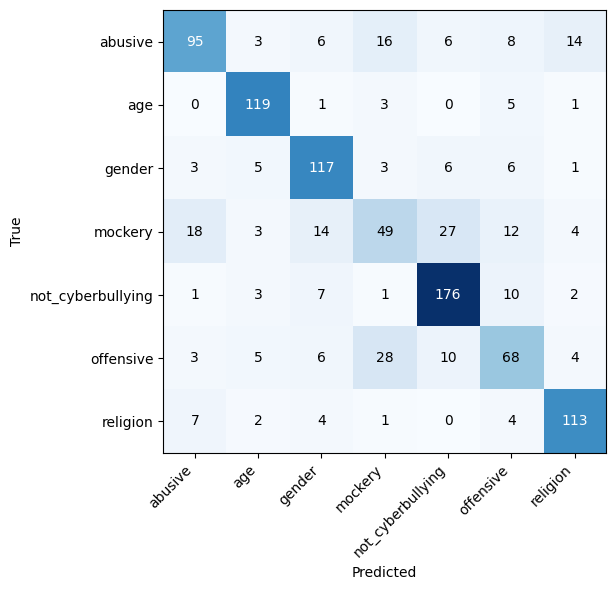

In [11]:
best = max(results, key=lambda n: results[n]['dev_macro_f1'])
print('Best on dev:', best)
print(classification_report(test['y'], predictions[best], target_names=labels, digits=3))
matrix = confusion_matrix(test['y'], predictions[best])
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(matrix, cmap='Blues')
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, matrix[i, j], ha='center', va='center', color='white' if matrix[i, j] > matrix.max() / 2 else 'black')
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
plt.tight_layout()
plt.savefig('outputs/confusion.png', dpi=160)
plt.show()

In [12]:
report = {n: classification_report(test['y'], p, target_names=labels, output_dict=True) for n, p in predictions.items()}
per_class = pd.DataFrame({n: {l: r[l]['f1-score'] for l in labels} for n, r in report.items()}).round(3)
display(per_class)
print(json.dumps({'stats': stats, 'results': results, 'best': best, 'confusion': matrix.tolist(), 'labels': labels, 'per_class': per_class.to_dict()}))

,Naive Bayes,Logistic Regression,Linear SVM,BiLSTM,mBERT,HingRoBERTa
abusive,0.617,0.672,0.691,0.500,0.662,0.701
age,0.808,0.882,0.885,0.745,0.774,0.849
gender,0.767,0.785,0.791,0.665,0.676,0.801
mockery,0.407,0.442,0.430,0.317,0.269,0.288
not_cyberbullying,0.807,0.789,0.828,0.746,0.719,0.802
offensive,0.575,0.541,0.574,0.575,0.482,0.522
religion,0.828,0.848,0.837,0.712,0.869,0.862


{"stats": {"raw_train": 7400, "raw_test": 1000, "after_length_filter": 7302, "after_dedup": 7274, "after_test_overlap_removed": 7243, "fit": 6518, "dev": 725, "test": 1000}, "results": {"Naive Bayes": {"accuracy": 0.71, "macro_f1": 0.6869563718597969, "weighted_f1": 0.6964718546729918, "dev_macro_f1": 0.7968666873171397, "seconds": 12.004161357879639}, "Logistic Regression": {"accuracy": 0.722, "macro_f1": 0.7083794735110845, "weighted_f1": 0.7159575422411129, "dev_macro_f1": 0.8444752671600994, "seconds": 84.7544059753418}, "Linear SVM": {"accuracy": 0.737, "macro_f1": 0.7193063643953356, "weighted_f1": 0.728897338784131, "dev_macro_f1": 0.8498978723204906, "seconds": 6.17036509513855}, "BiLSTM": {"accuracy": 0.62, "macro_f1": 0.6085978995199444, "weighted_f1": 0.617925385192498, "dev_macro_f1": 0.7232536115936173, "seconds": 7.508560419082642}, "mBERT": {"accuracy": 0.651, "macro_f1": 0.6356796691054584, "weighted_f1": 0.6445202864076747, "dev_macro_f1": 0.8005483031217218, "seconds"